In [1]:
# 📚 Libraries
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
from tqdm import tqdm

# 📂 Paths
DETECTION_DATASET_DIR = r"D:\luna16\detection_patches"

# 📋 Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Using device: {device}")


✅ Using device: cuda


In [3]:
class DetectionDataset(Dataset):
    def __init__(self, root_dir):
        """
        root_dir: path to detection_patches/
        """
        self.root_dir = root_dir
        
        # Collect positive and negative file paths
        self.positive_paths = [os.path.join(root_dir, "positive", f) for f in os.listdir(os.path.join(root_dir, "positive")) if f.endswith(".pt")]
        self.negative_paths = [os.path.join(root_dir, "negative", f) for f in os.listdir(os.path.join(root_dir, "negative")) if f.endswith(".pt")]
        
        self.all_paths = self.positive_paths + self.negative_paths
        self.labels = [1]*len(self.positive_paths) + [0]*len(self.negative_paths)

        print(f"✅ Dataset initialized: {len(self.positive_paths)} positives, {len(self.negative_paths)} negatives.")

    def __len__(self):
        return len(self.all_paths)

    def __getitem__(self, idx):
        path = self.all_paths[idx]
        label = self.labels[idx]
        
        patch = torch.load(path)  # (1, 64, 64, 64)
        
        return patch, label


In [25]:
from torch.utils.data import DataLoader, random_split
from collections import Counter
import torch

# 📋 Parameters
BATCH_SIZE = 16
VAL_SPLIT = 0.2  # 20% for validation
TEST_SPLIT = 0.1  # 10% for test

# 📦 Create dataset instance
full_dataset = DetectionDataset(root_dir=DETECTION_DATASET_DIR)

# 📊 Compute class distribution
class_counts = Counter(full_dataset.labels)
n_neg = class_counts[0]
n_pos = class_counts[1]

# 🧮 Inverse frequency weights
weight_neg = n_pos / (n_pos + n_neg)
weight_pos = n_neg / (n_pos + n_neg)

# 🔢 Create weight tensor for loss
alpha_tensor = torch.tensor([weight_neg, weight_pos], dtype=torch.float32).to(device)

print(f"📊 Class counts → Negatives: {n_neg}, Positives: {n_pos}")
print(f"✅ Class Weights → weight_neg: {weight_neg:.4f}, weight_pos: {weight_pos:.4f}")

# ✂️ Compute split sizes
total_size = len(full_dataset)
test_size = int(total_size * TEST_SPLIT)
val_size = int(total_size * VAL_SPLIT)
train_size = total_size - val_size - test_size

# 📦 Split into train, val, test
generator = torch.Generator().manual_seed(42)  # reproducible splits
train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, [train_size, val_size, test_size], generator=generator
)

# 📦 Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

# ✅ Logging
print(f"✅ DataLoaders ready:")
print(f"   - {len(train_loader)} batches for training")
print(f"   - {len(val_loader)} batches for validation")
print(f"   - {len(test_loader)} batches for testing")


✅ Dataset initialized: 1215 positives, 8000 negatives.
📊 Class counts → Negatives: 8000, Positives: 1215
✅ Class Weights → weight_neg: 0.1319, weight_pos: 0.8681
✅ DataLoaders ready:
   - 404 batches for training
   - 116 batches for validation
   - 58 batches for testing


In [29]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay
import numpy as np

# 🛠️ 1. Load your model
def load_model(model_class, path, device):
    model = model_class().to(device)
    model.load_state_dict(torch.load(path))
    model.eval()
    print(f"✅ Model loaded from {path}")
    return model

# 🛠️ 2. Evaluate on validation set
def evaluate_model(model, val_loader, device, num_classes=2):
    model.eval()

    all_preds = []
    all_probs = []
    all_labels = []

    with torch.no_grad():
        for val_x, val_y in val_loader:
            val_x = val_x.to(device)
            val_y = val_y.to(device)

            outputs = model(val_x)
            probs = torch.softmax(outputs, dim=1)

            preds = outputs.argmax(dim=1)

            all_probs.append(probs.cpu())
            all_preds.append(preds.cpu())
            all_labels.append(val_y.cpu())

    all_preds = torch.cat(all_preds)
    all_probs = torch.cat(all_probs)
    all_labels = torch.cat(all_labels)

    return all_labels.numpy(), all_preds.numpy(), all_probs.numpy()

# 🛠️ 3. Plot Loss and Accuracy Curves
def plot_loss_accuracy(train_losses, val_losses, train_accuracies, val_accuracies):
    epochs = range(1, len(train_losses) + 1)

    plt.figure(figsize=(14,5))
    
    # Loss
    plt.subplot(1,2,1)
    plt.plot(epochs, train_losses, label='Train Loss')
    plt.plot(epochs, val_losses, label='Val Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training vs Validation Loss')
    plt.legend()

    # Accuracy
    plt.subplot(1,2,2)
    plt.plot(epochs, train_accuracies, label='Train Acc')
    plt.plot(epochs, val_accuracies, label='Val Acc')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.title('Training vs Validation Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

# 🛠️ 4. Plot ROC Curve
def plot_roc_curve(y_true, y_probs, num_classes=2):
    plt.figure(figsize=(8,6))
    
    y_true_onehot = np.eye(num_classes)[y_true]

    for i in range(num_classes):
        fpr, tpr, _ = roc_curve(y_true_onehot[:, i], y_probs[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'Class {i} (AUC = {roc_auc:.2f})')

    plt.plot([0,1], [0,1], linestyle='--', color='gray')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve by Class')
    plt.legend()
    plt.show()

# 🛠️ 5. Plot Confusion Matrix
def plot_confusion(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap='Blues')
    plt.title('Confusion Matrix')
    plt.show()

# 🏁 Full Evaluation Runner
def full_evaluation(model_class, model_path, train_losses, val_losses, train_accuracies, val_accuracies, val_loader, device):

    # Load model
    model = load_model(model_class, model_path, device)

    # Plot Loss and Accuracy
    plot_loss_accuracy(train_losses, val_losses, train_accuracies, val_accuracies)

    # Evaluate
    y_true, y_pred, y_probs = evaluate_model(model, val_loader, device)

    # Plot ROC Curve
    plot_roc_curve(y_true, y_probs, num_classes=2)

    # Plot Confusion Matrix
    plot_confusion(y_true, y_pred)


In [31]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class DoubleConv(nn.Module):
    """(convolution => [BN] => ReLU) * 2"""
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.double_conv = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

class UNet3DClassifier(nn.Module):
    def __init__(self, n_classes=2):
        super(UNet3DClassifier, self).__init__()

        self.enc1 = DoubleConv(1, 32)
        self.pool1 = nn.MaxPool3d(2)

        self.enc2 = DoubleConv(32, 64)
        self.pool2 = nn.MaxPool3d(2)

        self.enc3 = DoubleConv(64, 128)
        self.pool3 = nn.MaxPool3d(2)

        # bottleneck
        self.bottleneck = DoubleConv(128, 256)

        # Instead of decoder → classification head
        self.avgpool = nn.AdaptiveAvgPool3d((1, 1, 1))
        self.fc = nn.Linear(256, n_classes)

    def forward(self, x):
        x = self.enc1(x)
        x = self.pool1(x)

        x = self.enc2(x)
        x = self.pool2(x)

        x = self.enc3(x)
        x = self.pool3(x)

        x = self.bottleneck(x)

        x = self.avgpool(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


In [43]:
# Create model
model = UNet3DClassifier(n_classes=2).to(device)

# Optimizer and Loss
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)


🔵 Epoch 1/20:   0%|                                                                           | 0/404 [00:00<?, ?it/s]C:\Users\Adem Tounsi\AppData\Local\Temp\ipykernel_16408\4219369181.py:24: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue 

✅ Epoch [1/20] - Train Loss: 0.0404 - Train Acc: 59.70% | Val Loss: 0.0354 - Val Acc: 72.06%
💾 Best model saved!


🔵 Epoch 2/20: 100%|█████████████████████████████████████████| 404/404 [32:07<00:00,  4.77s/it, loss=0.00705, acc=61.8]


✅ Epoch [2/20] - Train Loss: 0.0375 - Train Acc: 61.76% | Val Loss: 0.0335 - Val Acc: 66.20%
💾 Best model saved!


🔵 Epoch 3/20: 100%|█████████████████████████████████████████| 404/404 [31:59<00:00,  4.75s/it, loss=0.00696, acc=62.5]


...

✅ Epoch [18/20] - Train Loss: 0.0015 - Train Acc: 99.32% | Val Loss: 0.0117 - Val Acc: 97.78%
⏳ Early stop patience: 3/7


🔵 Epoch 19/20: 100%|███████████████████████████████████████| 404/404 [31:36<00:00,  4.69s/it, loss=0.000355, acc=99.1]


✅ Epoch [19/20] - Train Loss: 0.0019 - Train Acc: 99.10% | Val Loss: 0.0119 - Val Acc: 98.21%
⏳ Early stop patience: 4/7


🔵 Epoch 20/20: 100%|███████████████████████████████████████| 404/404 [30:53<00:00,  4.59s/it, loss=0.000259, acc=99.3]


✅ Epoch [20/20] - Train Loss: 0.0014 - Train Acc: 99.29% | Val Loss: 0.0090 - Val Acc: 97.88%
⏳ Early stop patience: 5/7


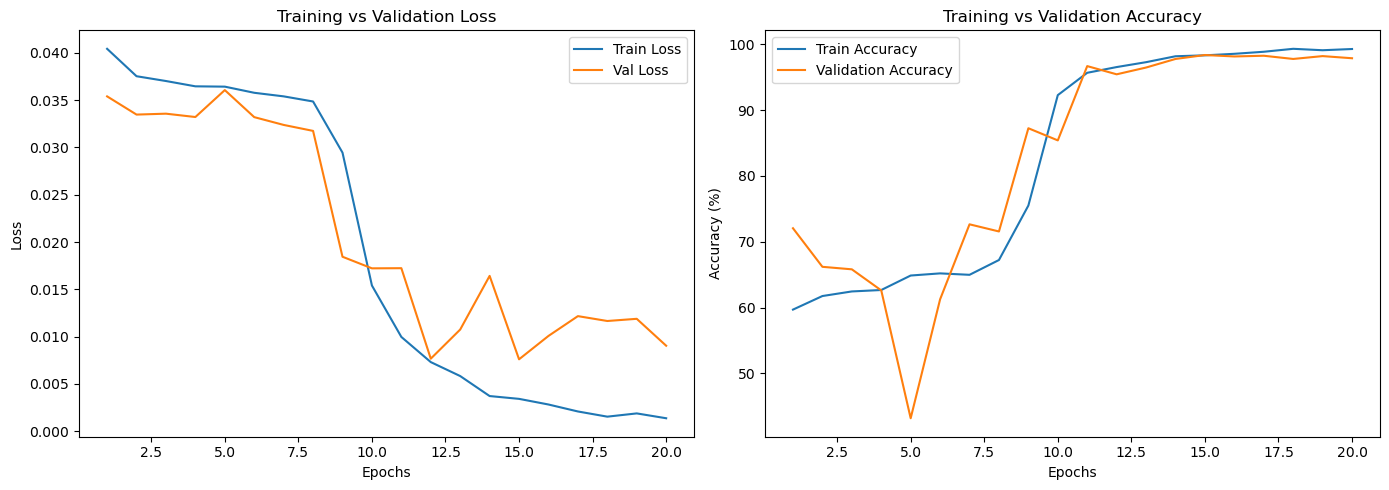

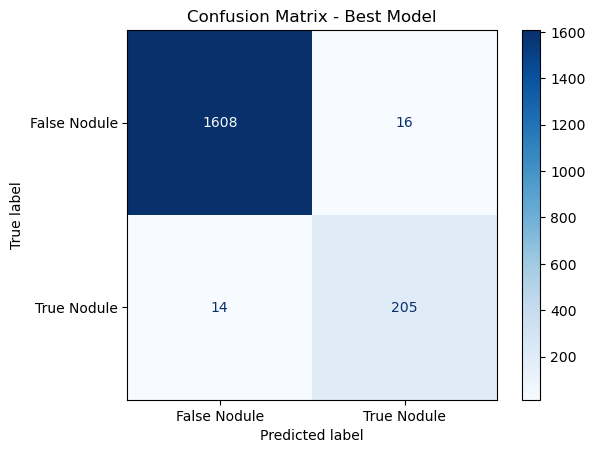

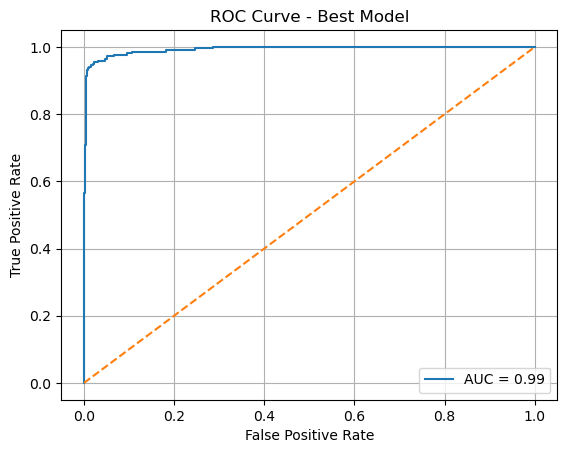

✅ Final Validation Accuracy: 97.88%
✅ Final AUC Score: 0.9928


In [48]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, roc_auc_score
from tqdm import tqdm
import os

# 🧠 Focal Loss Class (keep it)
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2, reduction='mean'):
        """
        alpha: tensor([weight_neg, weight_pos]) for class 0 and 1
        gamma: focusing parameter
        """
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        # inputs: [B, C], targets: [B]
        probs = torch.softmax(inputs, dim=1)              # [B, C]
        probs_true = probs.gather(1, targets.unsqueeze(1)).squeeze(1)  # [B]

        if self.alpha is not None:
            alpha_factor = self.alpha[targets]  # per-sample weight based on class
        else:
            alpha_factor = 1.0

        focal_term = (1 - probs_true) ** self.gamma
        loss = -alpha_factor * focal_term * torch.log(probs_true + 1e-8)

        return loss.mean() if self.reduction == 'mean' else loss.sum()


# 📦 Load your UNet3DClassifier model
model = UNet3DClassifier(n_classes=2).to(device)

# 📂 Folder to save best model and plots
SAVE_DIR = "outputs"
os.makedirs(SAVE_DIR, exist_ok=True)

# 📋 Optimizer and Loss
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
criterion = FocalLoss(alpha=alpha_tensor, gamma=2).to(device)

# 📋 Training parameters
num_epochs = 20
best_val_loss = float('inf')
patience = 7
early_stop_counter = 0

# 📦 Tracking lists
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

# ⚡ Final best model evaluation
final_y_true = []
final_y_pred = []
final_y_probs = []

# 📦 Training Loop
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    loop = tqdm(train_loader, desc=f"🔵 Epoch {epoch+1}/{num_epochs}", leave=True)

    for batch_x, batch_y in loop:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        preds = outputs.argmax(dim=1)
        correct += (preds == batch_y).sum().item()
        total += batch_y.size(0)

        loop.set_postfix({
            'loss': running_loss / (total / batch_x.size(0)),
            'acc': 100. * correct / total
        })

    avg_train_loss = running_loss / len(train_loader)
    avg_train_acc = 100. * correct / total

    train_losses.append(avg_train_loss)
    train_accuracies.append(avg_train_acc)

    # 📋 Validation phase
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    temp_y_true = []
    temp_y_pred = []
    temp_y_probs = []

    with torch.no_grad():
        for val_x, val_y in val_loader:
            val_x = val_x.to(device)
            val_y = val_y.to(device)

            val_outputs = model(val_x)
            val_loss = criterion(val_outputs, val_y)

            val_running_loss += val_loss.item()

            val_preds = val_outputs.argmax(dim=1)
            val_correct += (val_preds == val_y).sum().item()
            val_total += val_y.size(0)

            temp_y_true.extend(val_y.cpu().numpy())
            temp_y_pred.extend(val_preds.cpu().numpy())
            probs = torch.softmax(val_outputs, dim=1)[:,1]  # probability of class 1
            temp_y_probs.extend(probs.cpu().numpy())

    avg_val_loss = val_running_loss / len(val_loader)
    avg_val_acc = 100. * val_correct / val_total

    val_losses.append(avg_val_loss)
    val_accuracies.append(avg_val_acc)

    print(f"✅ Epoch [{epoch+1}/{num_epochs}] - Train Loss: {avg_train_loss:.4f} - Train Acc: {avg_train_acc:.2f}% | Val Loss: {avg_val_loss:.4f} - Val Acc: {avg_val_acc:.2f}%")

    # 🔥 Save best model
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        early_stop_counter = 0
        torch.save(model.state_dict(), os.path.join(SAVE_DIR, "best_model_UNet3DClassifier1.pth"))
        print("💾 Best model saved!")

        final_y_true = temp_y_true
        final_y_pred = temp_y_pred
        final_y_probs = temp_y_probs

    else:
        early_stop_counter += 1
        print(f"⏳ Early stop patience: {early_stop_counter}/{patience}")

    if early_stop_counter >= patience:
        print("🚨 Early stopping triggered.")
        break

# 📈 Plot and Save Loss and Accuracy Curves
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(epochs, train_losses, label='Train Loss')
plt.plot(epochs, val_losses, label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(epochs, train_accuracies, label='Train Accuracy')
plt.plot(epochs, val_accuracies, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Training vs Validation Accuracy')
plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "loss_accuracy_curves.png"))
plt.show()

# 📈 Confusion Matrix
cm = confusion_matrix(final_y_true, final_y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["False Nodule", "True Nodule"])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Best Model')
plt.grid(False)
plt.savefig(os.path.join(SAVE_DIR, "confusion_matrix.png"))
plt.show()

# 📈 ROC Curve
fpr, tpr, _ = roc_curve(final_y_true, final_y_probs)
roc_auc = roc_auc_score(final_y_true, final_y_probs)

plt.figure()
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Best Model')
plt.legend()
plt.grid()
plt.savefig(os.path.join(SAVE_DIR, "roc_curve.png"))
plt.show()

print(f"✅ Final Validation Accuracy: {val_accuracies[-1]:.2f}%")
print(f"✅ Final AUC Score: {roc_auc:.4f}")


🧪 Loading best model for test evaluation...


C:\Users\Adem Tounsi\AppData\Local\Temp\ipykernel_16408\3490664883.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(os.path.join(SAVE_DIR

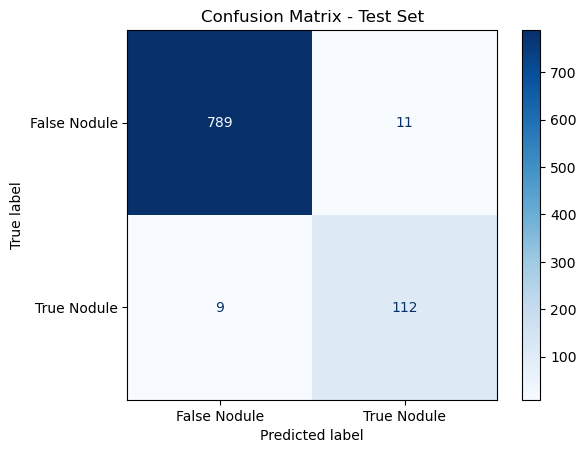

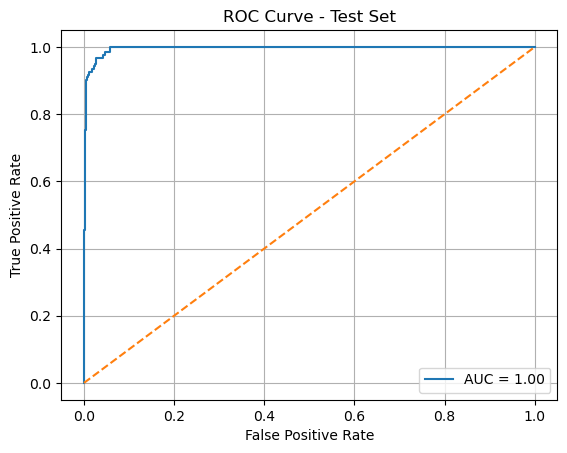

✅ Final Test Accuracy: 97.83%
✅ Final Test AUC Score: 0.9961


In [49]:
# 🧪 Load Best Model for Test
print("🧪 Loading best model for test evaluation...")
model.load_state_dict(torch.load(os.path.join(SAVE_DIR, "best_model_UNet3DClassifier1.pth")))
model.eval()

test_y_true = []
test_y_pred = []
test_y_probs = []

with torch.no_grad():
    for test_x, test_y in test_loader:
        test_x = test_x.to(device)
        test_y = test_y.to(device)

        test_outputs = model(test_x)
        test_preds = test_outputs.argmax(dim=1)
        probs = torch.softmax(test_outputs, dim=1)[:, 1]  # Prob for class 1

        test_y_true.extend(test_y.cpu().numpy())
        test_y_pred.extend(test_preds.cpu().numpy())
        test_y_probs.extend(probs.cpu().numpy())

# 📈 Test Results
test_cm = confusion_matrix(test_y_true, test_y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=test_cm, display_labels=["False Nodule", "True Nodule"])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Test Set')
plt.grid(False)
plt.savefig(os.path.join(SAVE_DIR, "test_confusion_matrix.png"))
plt.show()

# ROC + AUC
fpr, tpr, _ = roc_curve(test_y_true, test_y_probs)
test_auc = roc_auc_score(test_y_true, test_y_probs)

plt.figure()
plt.plot(fpr, tpr, label=f'AUC = {test_auc:.2f}')
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Set')
plt.legend()
plt.grid()
plt.savefig(os.path.join(SAVE_DIR, "test_roc_curve.png"))
plt.show()

# 📢 Final Test Results
test_accuracy = np.mean(np.array(test_y_pred) == np.array(test_y_true)) * 100
print(f"✅ Final Test Accuracy: {test_accuracy:.2f}%")
print(f"✅ Final Test AUC Score: {test_auc:.4f}")
